# What does the joint objective actually balance?

**Question:** How does changing only coupling length rescale the structural term and its derivatives?

**Level 2 — objective and derivatives**  
**Prerequisites:** joint inverse hypothesis, weighted least squares and directional derivatives; 35 min.

## Objectives

Separate data misfit, property regularization and structural coupling; trace the effect of coupling length on the product's structural term; distinguish gradient and Hessian-vector products from uncertainty and predictive scores.

## Setup

Install the exact notebook dependencies:

```bash
pip install numpy==2.2.6 scipy==1.15.2 matplotlib==3.10.8 simpeg==0.25.2 discretize==0.12.0
```

The same authored twelve-cell control, plan, active mask, density and susceptibility vectors are used throughout; there are no field data and the models are not refit.

## Data

The fixed control records receiver coordinates, source metadata, uncertainty declarations, twelve active cells and bounded physical-property vectors. These are authored synthetic inputs, not observations. The experiment uses the same acquisition and model arrays for every length so that the declared coupling length is the only varied factor.

## Method

A joint objective can be written φ = φd,ρ + φd,χ + βρRρ + βχRχ + λC. Each data term uses its modality-specific forward response and covariance; property regularizers encode separate assumptions; C expresses cross-gradient compatibility. This lesson isolates C and changes its declared length while keeping fields fixed. Here length enters with a fourth-power factor and normalization by active volume. This scale response belongs to the parameterization, not empirical preference.

The gradient is the first-order change of C at one model. The Hessian-vector product describes local second-order change along one direction. Neither is data covariance or posterior uncertainty. A finite-difference check can reveal derivative errors, but cannot establish optimization quality. Selecting λ or length requires a predefined validation design with independent observations and a decision rule.


In [1]:
# Import the pinned physical evaluator and show the runtime versions.
from pathlib import Path
import sys
from importlib.metadata import version
import numpy as np
import matplotlib.pyplot as plt

root = next(
    p for p in (Path.cwd(), *Path.cwd().parents) if (p / "data-pipeline/joint_survey_structure.py").is_file()
)
sys.path.insert(0, str(root / "data-pipeline"))
import joint_survey_plan as planner
import joint_survey_structure as physical_structure

print("NumPy", version("numpy"), "SimPEG", version("simpeg"), "discretize", version("discretize"))


NumPy 2.2.6 SimPEG 0.25.2 discretize 0.12.0


### The physical control remains fixed

The twelve active cells, receiver coordinates, bounds and property scales stay unchanged across requests. Coupling length is therefore the sole experimental factor. The six receivers per modality and noise declarations describe synthetic acquisition metadata; no observed residual enters the plotted sweep. This isolates regularizer scaling rather than comparing gravity and magnetic fits.


In [2]:
# Define a small authored ENU control and its declared physical scales.
receivers = np.array(
    [20, 30, 100, 50, 80, 110, -90, 40, 130, 10, -10, 150, 90, -50, 120, 130, 40, 160], dtype=float
).reshape(6, 3)
mag_receivers = receivers + [5, 0, 0]
src = dict(
    citation="Authored numerical control, not field data",
    raw_bytes=123,
    rights="private_use",
    correction_sha256="c" * 64,
)
g_source = dict(src, source_id="gravity", raw_sha256="a" * 64)
m_source = dict(src, source_id="magnetic", raw_sha256="b" * 64)
noise = dict(basis="measured_gaussian", cross_partition="declared_absent", citation="Authored error control")
noise_g = dict(noise, kind="diagonal_sd", unit="mGal")
noise_m = dict(noise, kind="diagonal_sd", unit="nT")
common = dict(reference_id="authored-local-enu", mask=np.zeros(6, bool), missing_reasons=("",) * 6)
common.update(groups=np.array([0, 0, 1, 1, 2, 2]), partition=np.array([0, 0, 1, 1, 2, 2]))
gravity = dict(common, source=g_source, component="gz_up", unit="mGal", receivers_m=receivers, noise=noise_g)
field = dict(amplitude_nt=50000.0, inclination_deg=60.0, declination_deg=12.0)


### Keep the data terms modality-specific

Gravity and magnetic observations have different units, operators, source assumptions and error structures. A defensible objective whitens each residual with its own covariance and reports the terms separately before adding property regularization and structural coupling. Otherwise a modality may dominate through units or sample count alone. This experiment plots only the cross-gradient term, not total-objective improvement.


In [3]:
# Preserve the declared scales and mesh ordering because both enter the discrete derivative.
magnetic = dict(
    common,
    source=m_source,
    component="linear_tmi",
    unit="nT",
    receivers_m=mag_receivers,
    noise=noise_m,
    inducing_field=field,
)
density = dict(
    lower=np.full(12, -1500.0),
    upper=np.full(12, 1500.0),
    start=np.zeros(12),
    reference=np.zeros(12),
    scale=750.0,
)
susceptibility = dict(
    lower=np.zeros(12),
    upper=np.full(12, 0.1),
    start=np.full(12, 0.005),
    reference=np.full(12, 0.005),
    scale=0.03,
)


### The plan digest anchors the comparison

The normalized plan digest records mesh and survey details consumed by the evaluator. Holding it fixed ensures later points use the same geometry and parameter ordering. A matching digest does not prove that this authored control resembles a real survey; it only prevents input changes from being mistaken for a length effect.


In [4]:
# Preserve the declared scales and mesh ordering because both enter the discrete derivative.
frame = dict(
    kind="local_cartesian",
    axes=("east", "north", "up"),
    length_unit="m",
    vertical_positive="up",
    reference_id="authored-local-enu",
)
frame.update(horizontal_datum="declared local origin", vertical_datum="declared elevation datum")
mesh = dict(
    origin_m=np.array([-140.0, -180.0, -260.0]),
    hx_m=np.array([40.0, 70.0, 90.0]),
    hy_m=np.array([30.0, 50.0]),
    hz_m=np.array([60.0, 110.0]),
    active=np.ones(12, bool),
)
prior = dict(
    density=density,
    susceptibility=susceptibility,
    lengths_m=np.array([60.0, 110.0, 75.0]),
    coupling_length_m=100.0,
    basis="Declared physical scales",
)


### Step 1 — establish the baseline

Evaluate the structural term once at the declared baseline length. It anchors the sweep but is not a benchmark. Fixed fields mean this value cannot show whether they fit observed gravity or magnetics, whether separate inversions agree, or whether coupling improves interpretation.


In [5]:
# Validate units, active cells, and source groups before evaluating a joint structural quantity.
policy = dict(
    name="joint-survey-l2-cross-gradient-1", seed=42, cell_order="x-fast", training="not_applicable_classical"
)
policy.update(group_scope="global_acquisition", modal_covariance="independent")
physical_request = dict(
    schema="joint-survey-plan-request-1",
    frame=frame,
    mesh=mesh,
    gravity=gravity,
    magnetic=magnetic,
    prior=prior,
    policy=policy,
)
physical_plan = planner.plan_joint_survey(physical_request)
physical_n = 12
physical_rho, physical_chi = np.linspace(-400.0, 500.0, 12), np.linspace(0.004, 0.045, 12) + 0.002 * np.sin(
    np.arange(12)
)
physical_direction = np.sin(np.arange(24) + 0.3) / np.linalg.norm(np.sin(np.arange(24) + 0.3))
print("authored active cells", int(physical_plan["mesh"]["active"].sum()), "receiver count", len(receivers))


authored active cells 12 receiver count 6


### Step 2 — vary coupling length alone

Build requests with identical fields and plan, changing only length. The fourth-power factor means equal length increments do not yield equal objective increments. This interval explains sensitivity; it is neither a field recommendation nor a hyperparameter search. No held-out data rank the points.


In [6]:
# Evaluate the baseline physical structural term.
r = physical_structure.evaluate_joint_structure(
    {
        "schema": "joint-survey-structure-request-1",
        "survey_request": physical_request,
        "density_kg_m3": physical_rho,
        "susceptibility_si": physical_chi,
        "direction_physical": physical_direction,
    }
)
print("objective", r["objective"], "plan", r["plan_sha256"])


objective 0.012770248999752326 plan c62903164d0f129d95137ffe16f334e3cf0d936d26f1f8fa04c6d4da3da9563c


### Step 3 — inspect local curvature

The Hessian-vector product describes how the structural penalty's gradient changes along one declared direction. It depends on scaling, mesh and direction. It is not covariance, an uncertainty interval or a full curvature spectrum; one vector cannot expose all weakly constrained model combinations.


In [7]:
# Change only coupling length across a declared sensitivity sweep.
from copy import deepcopy

lengths = np.array([50.0, 75.0, 100.0, 150.0, 200.0])
values = []
for length in lengths:
    q = deepcopy(physical_request)
    q["prior"]["coupling_length_m"] = float(length)
    values.append(
        physical_structure.evaluate_joint_structure(
            {
                "schema": "joint-survey-structure-request-1",
                "survey_request": q,
                "density_kg_m3": physical_rho,
                "susceptibility_si": physical_chi,
                "direction_physical": physical_direction,
            }
        )["objective"]
    )
print("length_m", lengths.tolist(), "objective", np.round(values, 8).tolist())


length_m [50.0, 75.0, 100.0, 150.0, 200.0] objective [0.00079814, 0.00404059, 0.01277025, 0.06464939, 0.20432398]


### Step 4 — check the first derivative

Compare the analytic directional derivative with a central finite difference at baseline. The gap tests local implementation for one perturbation size. Other directions, cancellation and nonsmooth behavior are not tested. This is evidence about a derivative, not full numerical analysis or a convergence guarantee.


In [8]:
# Re-evaluate the same physical fields with the opposite direction.
from copy import deepcopy

reverse_request = deepcopy(physical_request)
reverse_request["prior"]["coupling_length_m"] = 100.0
exact = np.asarray(r["exact_hessian_vector_physical"])
reverse_request_result = physical_structure.evaluate_joint_structure(
    {
        "schema": "joint-survey-structure-request-1",
        "survey_request": reverse_request,
        "density_kg_m3": physical_rho,
        "susceptibility_si": physical_chi,
        "direction_physical": -physical_direction,
    }
)
reverse_hv = np.asarray(reverse_request_result["exact_hessian_vector_physical"])
assert np.allclose(reverse_hv, -exact, rtol=1e-10, atol=1e-12)
print("odd Hessian-vector parity", float(np.max(np.abs(reverse_hv + exact))))


odd Hessian-vector parity 0.0


### Step 5 — keep plotted quantities distinct

The objective sweep is shown beside the baseline gradient norm. They play different mathematical roles; the horizontal line is not a target. A steep curve does not mean better data fit, and a small gradient does not prove a minimum of the full joint objective. Read each axis separately; the model is fixed.


In [9]:
# Verify the physical gradient with a central finite difference.
h = 1e-3


def f(a, b):
    return physical_structure.evaluate_joint_structure(
        {
            "schema": "joint-survey-structure-request-1",
            "survey_request": physical_request,
            "density_kg_m3": a,
            "susceptibility_si": b,
            "direction_physical": physical_direction,
        }
    )["objective"]


fd = (
    f(physical_rho + h * physical_direction[:physical_n], physical_chi + h * physical_direction[physical_n:])
    - f(physical_rho - h * physical_direction[:physical_n], physical_chi - h * physical_direction[physical_n:])
) / (2 * h)
print(
    "analytic directional derivative",
    float(np.dot(r["gradient_physical"], physical_direction)),
    "finite difference",
    fd,
)


analytic directional derivative 3.5699340755498583 finite difference 3.569933992523068


### Render the scale sweep and derivative reference

The two panels plot the freshly evaluated structural objective across coupling lengths and the gradient norm at the baseline. Keep their axes separate: a scale-dependent prior value and a local derivative magnitude are distinct diagnostics. The following figure interpretations discuss each panel independently.


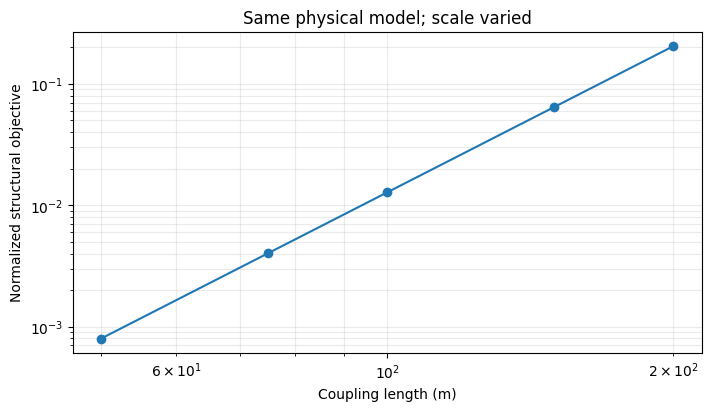

In [10]:
# Plot the computed response; changing this scale is not inversion tuning.
fig, ax = plt.subplots(figsize=(7, 4), constrained_layout=True)
ax.loglog(lengths, values, "o-")
ax.set(
    xlabel="Coupling length (m)",
    ylabel="Normalized structural objective",
    title="Same physical model; scale varied",
)
ax.grid(True, which="both", alpha=0.25)
plt.show()


### Figure 1 interpretation: objective scaling

The objective rises from 0.000798 at 50 m to 0.204324 at 200 m while the model fields remain fixed. This response exposes the declared fourth-power length scaling, not an improvement in gravity or magnetic fit. No model is reoptimized and no validation observations rank these settings. The curve documents parameterization sensitivity only.


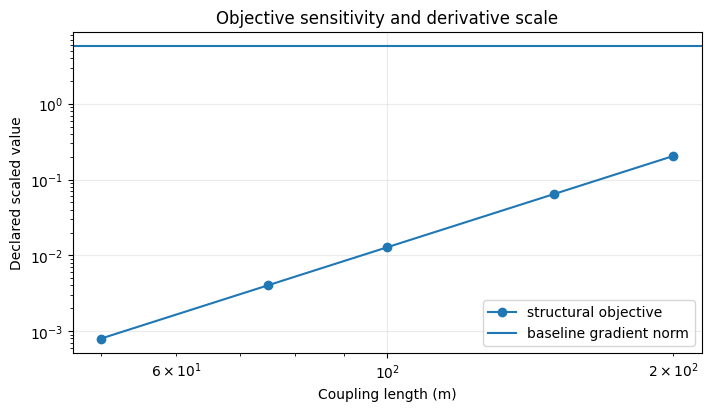

case joint-control-00 objective 32.97655447858452
component terms {'data_gravity': 18.89476419413715, 'regularization_gravity': 0.0, 'data_magnetic': 14.081790284447372, 'regularization_magnetic': 0.0, 'coupling': 0.0}


In [11]:
# Plot scale response beside the distinct derivative magnitude.
fig, ax = plt.subplots(figsize=(7, 4), constrained_layout=True)
ax.loglog(lengths, values, "o-", label="structural objective")
ax.axhline(np.linalg.norm(r["gradient_physical"]), label="baseline gradient norm")
ax.set(
    xlabel="Coupling length (m)",
    ylabel="Declared scaled value",
    title="Objective sensitivity and derivative scale",
)
ax.legend()
ax.grid(alpha=0.25)
plt.show()


# Build, plan, compile, and evaluate the actual product objective on identical synthetic inputs.
import joint_survey_cases, joint_survey_compiled, joint_survey_objective

joint_control = joint_survey_cases.make_joint_control(0)
joint_problem = joint_survey_compiled.compile_joint_development({
    "schema": "joint-survey-compile-request-1",
    "survey_request": joint_control["survey_request"],
    "development": joint_control["development"],
})
prior_product = joint_control["survey_request"]["prior"]
joint_result = joint_survey_objective.evaluate_joint_objective({
    "schema": "joint-survey-objective-request-1",
    "survey_request": joint_control["survey_request"],
    "development": joint_control["development"],
    "models": {
        "density_kg_m3": prior_product["density"]["start"],
        "susceptibility_si": prior_product["susceptibility"]["start"],
    },
    "direction_physical": np.zeros(24),
    "weights": {"beta_gravity": 1e-4, "beta_magnetic": 1e-4, "coupling": 0.1},
})
print("case", joint_control["case_id"], "objective", joint_result["objective"])
print("component terms", joint_result["terms"])
assert set(joint_result["terms"]) == {"data_gravity", "regularization_gravity", "data_magnetic", "regularization_magnetic", "coupling"}
assert joint_result["diagnostics"]["inverse_completed"] is False


### Figure 2 interpretation: baseline derivative

The gradient is evaluated at the baseline request and is not a target or a second objective curve. Its magnitude describes local change of the structural term along the declared model direction. It is neither uncertainty nor evidence of optimizer convergence. Reading it separately prevents visual scale from conflating derivative size with predictive quality.




## Results

**Answer:** With fields fixed, changing length from 50 to 200 m moves the computed structural objective from 0.00079814 to 0.20432398. This documents nonlinear scaling, not inversion or parameter selection.

## Summary

This notebook isolates coupling and derivatives. A real joint inversion must balance modality-specific misfits, covariances and regularization. Validation data, not the sensitivity curve's appearance, must support a selected scale.

## References

- Cockett et al. (2015), [SimPEG](https://doi.org/10.1016/j.cageo.2015.09.015)
- [SimPEG cross-gradient tutorial](https://docs.simpeg.xyz/latest/content/user-guide/tutorials/13_joint_inversion/plot_inv_3_cross_gradient_pf.html)
- `data-pipeline/joint_survey_plan.py`; `data-pipeline/joint_survey_structure.py`


The product objective reports `data_gravity`, `data_magnetic`, `regularization_gravity`, `regularization_magnetic` and `coupling` for one compiled initial model. In this control the coupling term is zero at the starting state; the weighted total is not a fitted result.